<a href="https://colab.research.google.com/github/noorrami/ptbxl-ecg-classification/blob/main/notebooks/02_data_pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PTB-XL ECG Classification

## Notebook 02 — Patient-Safe Data Pipeline and ECG Preprocessing

**Course:** ECOM 6306 — Supervised Machine Learning  
**Dataset:** PTB-XL v1.0.3  
**Environment:** Google Colab  
**Project Phase:** Data Engineering and Preprocessing

### Objective

Implement a reproducible data pipeline for patient-independent ECG classification using the validated strict binary cohort.

### Scope

- Reconstruct official training, validation, and test partitions.
- Verify patient-level and record-level separation.
- Retrieve and validate 12-lead ECG recordings.
- Standardize signal tensor dimensions.
- Fit preprocessing statistics exclusively on training data.
- Prepare reusable datasets for subsequent machine learning experiments.

### Experimental Constraints

The test partition must remain excluded from model selection, hyperparameter optimization, and learned preprocessing estimation.

**Expected Outputs:** Validated split manifests, waveform quality-control results, training-fitted normalization parameters, and reproducible data-loading utilities.

Phase 0: Dependency Installation

In [1]:
%pip install -q wfdb pandas numpy matplotlib scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 2.6 MB/s eta 0:00:00


Phase 1: Environment and Project Paths

In [3]:
from pathlib import Path
import json
import hashlib
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb

from sklearn.preprocessing import StandardScaler
from google.colab import drive

drive.mount("/content/drive")

SEED = 42
np.random.seed(SEED)

ROOT = Path("/content/drive/MyDrive/ML_Master_Project")
AUDIT = ROOT / "results" / "dataset_audit"
RAW = ROOT / "data" / "raw" / "ptb-xl"
PROCESSED = ROOT / "data" / "processed"
RESULTS = ROOT / "results" / "data_pipeline"
ARTIFACTS = ROOT / "artifacts"

for path in [RAW, PROCESSED, RESULTS, ARTIFACTS]:
    path.mkdir(parents=True, exist_ok=True)

BASE_URL = "https://physionet.org/files/ptb-xl/1.0.3"

print("Project initialized.")
print("WFDB:", wfdb.__version__)
print("Raw data:", RAW)

Mounted at /content/drive
Project initialized.
WFDB: 4.3.1
Raw data: /content/drive/MyDrive/ML_Master_Project/data/raw/ptb-xl


Phase 2: Validated Cohort Loading

In [4]:
cohort_path = AUDIT / "strict_binary_cohort.csv"

assert cohort_path.exists(), (
    "Missing strict_binary_cohort.csv. "
    "Complete Day 02 Phase 17 first."
)

cohort = pd.read_csv(
    cohort_path,
    index_col="ecg_id"
)

required_columns = [
    "patient_id",
    "strat_fold",
    "target",
    "filename_lr"
]

assert all(
    col in cohort.columns
    for col in required_columns
)

assert cohort.index.is_unique
assert cohort["patient_id"].notna().all()
assert cohort["filename_lr"].notna().all()
assert cohort["target"].isin([0, 1]).all()

print("Records:", len(cohort))
print("Patients:", cohort["patient_id"].nunique())

display(cohort[required_columns].head())

Records: 11601
Patients: 10652


,patient_id,strat_fold,target,filename_lr
ecg_id,,,,
1,15709.0,3,0,records100/00000/00001_lr
2,13243.0,2,0,records100/00000/00002_lr
3,20372.0,5,0,records100/00000/00003_lr
4,17014.0,3,0,records100/00000/00004_lr
5,17448.0,4,0,records100/00000/00005_lr


**Phase 3: Official Train / Validation / Test Split**


The dataset is partitioned using the predefined PTB-XL stratification folds: folds 1–8 for training, fold 9 for validation, and fold 10 for final testing.

This protocol preserves the dataset's patient-level separation and provides consistent evaluation partitions across all candidate models.

The test set is reserved for final evaluation and must not influence preprocessing decisions, feature selection, hyperparameter optimization, or model selection.

In [5]:
train_df = cohort[
    cohort["strat_fold"].between(1, 8)
].copy()

val_df = cohort[
    cohort["strat_fold"] == 9
].copy()

test_df = cohort[
    cohort["strat_fold"] == 10
].copy()

splits = {
    "train": train_df,
    "validation": val_df,
    "test": test_df
}

for name, subset in splits.items():
    print(
        f"{name:12s}",
        f"records={len(subset):5d}",
        f"patients={subset['patient_id'].nunique():5d}"
    )

assert sum(len(x) for x in splits.values()) == len(cohort)
assert all(len(x) > 0 for x in splits.values())

train        records= 9286 patients= 8522
validation   records= 1147 patients= 1073
test         records= 1168 patients= 1057


**Phase 4: Patient and Record Leakage Tests**

Multiple ECG recordings may originate from the same patient. If recordings from one patient appear in both training and evaluation partitions, a model may exploit patient-specific characteristics rather than learn patterns that generalize to unseen patients.

To prevent this form of data leakage, the pipeline verifies that patient identifiers and ECG record identifiers are mutually exclusive across all partitions.

**Validation criterion:** No patient or ECG record may appear in more than one partition.

In [6]:
def verify_disjoint_splits(splits):
    names = list(splits)

    for i, name_a in enumerate(names):
        for name_b in names[i + 1:]:
            a = splits[name_a]
            b = splits[name_b]

            shared_patients = (
                set(a["patient_id"])
                & set(b["patient_id"])
            )

            shared_records = set(a.index) & set(b.index)

            assert not shared_patients, (
                f"Patient leakage: {name_a} / {name_b}"
            )

            assert not shared_records, (
                f"Record leakage: {name_a} / {name_b}"
            )

    return True


assert verify_disjoint_splits(splits)

print("PASS: No patient overlap.")
print("PASS: No ECG record overlap.")

PASS: No patient overlap.
PASS: No ECG record overlap.


Phase 5: Class Distribution by Split

In [7]:
summary = []

for name, subset in splits.items():
    counts = subset["target"].value_counts()

    summary.append({
        "split": name,
        "records": len(subset),
        "patients": subset["patient_id"].nunique(),
        "NORM": int(counts.get(0, 0)),
        "MI": int(counts.get(1, 0)),
        "MI_percent": round(
            100 * (subset["target"] == 1).mean(), 2
        )
    })

split_summary = pd.DataFrame(summary)

display(split_summary)

split_summary.to_csv(
    RESULTS / "split_summary.csv",
    index=False
)

,split,records,patients,NORM,MI,MI_percent
0,train,9286,8522,7243,2043,22.00
1,validation,1147,1073,914,233,20.31
2,test,1168,1057,912,256,21.92


Phase 6: Split Manifest Export

In [8]:
for name, subset in splits.items():
    subset.to_csv(
        PROCESSED / f"{name}_manifest.csv",
        index=True
    )

manifest_hashes = {}

for name in splits:
    path = PROCESSED / f"{name}_manifest.csv"

    manifest_hashes[name] = hashlib.sha256(
        path.read_bytes()
    ).hexdigest()

with open(
    RESULTS / "manifest_hashes.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(manifest_hashes, f, indent=4)

print("Split manifests and SHA-256 hashes saved.")

Split manifests and SHA-256 hashes saved.


**Phase 7: ECG Waveform Retrieval**


PTB-XL provides standardized 12-lead ECG recordings at multiple sampling frequencies. This project initially uses the 100 Hz representation, with each 10-second recording represented as a matrix of 1,000 time samples and 12 channels.

$$
  X_i \in \mathbb{R}^{1000 \times 12}
$$

The loader validates sampling frequency, signal dimensions, and lead ordering before accepting a recording.

These checks ensure consistent input representations and prevent silent errors caused by incompatible waveform files.

In [9]:
EXPECTED_LEADS = [
    "I", "II", "III",
    "aVR", "aVL", "aVF",
    "V1", "V2", "V3",
    "V4", "V5", "V6"
]


def download_ecg_record(relative_path):
    relative_path = str(relative_path)

    if not relative_path.startswith("records100/"):
        raise ValueError(
            f"Unexpected ECG record path: {relative_path}"
        )

    for extension in [".hea", ".dat"]:
        remote_file = relative_path + extension
        local_file = RAW / remote_file

        local_file.parent.mkdir(
            parents=True,
            exist_ok=True
        )

        if not local_file.exists():
            url = f"{BASE_URL}/{remote_file}"
            urllib.request.urlretrieve(url, local_file)

    return RAW / relative_path


def load_ecg_record(relative_path):
    local_path = download_ecg_record(relative_path)

    record = wfdb.rdrecord(str(local_path))

    signal = record.p_signal.astype(np.float32)

    if record.fs != 100:
        raise ValueError(
            f"Unexpected sampling frequency: {record.fs}"
        )

    if signal.shape != (1000, 12):
        raise ValueError(
            f"Unexpected ECG shape: {signal.shape}"
        )

    lead_names = [
        name.upper()
        for name in record.sig_name
    ]

    if lead_names != [x.upper() for x in EXPECTED_LEADS]:
        raise ValueError(
            f"Unexpected lead ordering: {record.sig_name}"
        )

    return signal

**Phase 8: Development Sample Selection**


A small, class-balanced pilot subset is selected exclusively from the training and validation partitions to verify the data pipeline before processing the complete dataset.

This pilot is intended for software validation, not for estimating final predictive performance.

The final experiments will use the complete eligible training and validation partitions, with class imbalance handled through appropriate training strategies and evaluation metrics.

In [10]:
PILOT_TRAIN_PER_CLASS = 8
PILOT_VAL_PER_CLASS = 4


def sample_by_class(dataframe, n_per_class, seed=42):
    parts = []

    for target in [0, 1]:
        class_df = dataframe[
            dataframe["target"] == target
        ]

        parts.append(
            class_df.sample(
                n=n_per_class,
                random_state=seed
            )
        )

    return pd.concat(parts).sort_index()


pilot_train = sample_by_class(
    train_df,
    PILOT_TRAIN_PER_CLASS,
    SEED
)

pilot_val = sample_by_class(
    val_df,
    PILOT_VAL_PER_CLASS,
    SEED
)

print("Pilot training records:", len(pilot_train))
print("Pilot validation records:", len(pilot_val))

Pilot training records: 16
Pilot validation records: 8


Phase 9: Waveform Loading and Label Alignment

In [11]:
def load_waveform_batch(dataframe):
    signals = []
    labels = []
    record_ids = []

    for ecg_id, row in dataframe.iterrows():
        signal = load_ecg_record(
            row["filename_lr"]
        )

        signals.append(signal)
        labels.append(int(row["target"]))
        record_ids.append(int(ecg_id))

    X = np.stack(signals).astype(np.float32)
    y = np.asarray(labels, dtype=np.int64)
    ids = np.asarray(record_ids)

    assert X.shape == (len(dataframe), 1000, 12)
    assert y.shape == (len(dataframe),)
    assert np.isfinite(X).all()

    return X, y, ids


X_train_pilot, y_train_pilot, train_ids = (
    load_waveform_batch(pilot_train)
)

X_val_pilot, y_val_pilot, val_ids = (
    load_waveform_batch(pilot_val)
)

print("Training signals:", X_train_pilot.shape)
print("Validation signals:", X_val_pilot.shape)
print("Training labels:", y_train_pilot.shape)
print("Validation labels:", y_val_pilot.shape)

Training signals: (16, 1000, 12)
Validation signals: (8, 1000, 12)
Training labels: (16,)
Validation labels: (8,)


**Phase 10: ECG Signal Quality Control**


ECG waveform integrity is assessed before normalization or model training.

The quality-control procedure checks signal dimensions, finite numerical values, amplitude ranges, and constant channels.

These tests identify potential data corruption and basic structural abnormalities. They do not constitute comprehensive clinical signal-quality assessment or artifact detection.

Any future exclusion criteria must be explicitly defined, documented, and applied consistently without using held-out test performance to guide decisions.

In [12]:
def signal_quality_report(X, record_ids):
    rows = []

    for signal, ecg_id in zip(X, record_ids):
        rows.append({
            "ecg_id": int(ecg_id),
            "finite": bool(np.isfinite(signal).all()),
            "min_value": float(np.nanmin(signal)),
            "max_value": float(np.nanmax(signal)),
            "max_abs_amplitude": float(
                np.nanmax(np.abs(signal))
            ),
            "constant_channels": int(
                np.sum(np.ptp(signal, axis=0) == 0)
            ),
            "shape_valid": signal.shape == (1000, 12)
        })

    return pd.DataFrame(rows)


qc_train = signal_quality_report(
    X_train_pilot, train_ids
)

qc_val = signal_quality_report(
    X_val_pilot, val_ids
)

display(qc_train)
display(qc_val)

assert qc_train["finite"].all()
assert qc_val["finite"].all()
assert qc_train["shape_valid"].all()
assert qc_val["shape_valid"].all()

print("PASS: Basic signal integrity checks.")

,ecg_id,finite,min_value,max_value,max_abs_amplitude,constant_channels,shape_valid
0,1306,True,-1.048,1.560,1.560,0,True
1,3765,True,-1.865,2.364,2.364,0,True
2,3847,True,-1.391,1.452,1.452,0,True
3,4197,True,-2.162,1.655,2.162,0,True
4,6868,True,-2.834,2.328,2.834,0,True
5,7862,True,-1.234,1.695,1.695,0,True
6,8239,True,-1.239,1.851,1.851,0,True
7,10669,True,-1.518,1.078,1.518,0,True
8,11968,True,-1.218,1.207,1.218,0,True
9,12952,True,-1.882,2.178,2.178,0,True


,ecg_id,finite,min_value,max_value,max_abs_amplitude,constant_channels,shape_valid
0,1159,True,-4.998,1.376,4.998,0,True
1,7183,True,-0.649,1.079,1.079,0,True
2,7435,True,-1.702,2.777,2.777,0,True
3,7608,True,-0.865,1.101,1.101,0,True
4,8172,True,-1.741,1.604,1.741,0,True
5,19136,True,-1.910,2.712,2.712,0,True
6,19632,True,-1.928,1.319,1.928,0,True
7,21765,True,-3.703,1.036,3.703,0,True


PASS: Basic signal integrity checks.


**Phase 11: Training-Only Channel Normalization**


Channel-wise standardization is applied to normalize ECG amplitudes while preserving the temporal structure of each recording.

For each ECG channel \(c\), the mean and standard deviation are estimated exclusively from the training partition:

$$
\mu_c^{\text{train}} =
\frac{1}{NT}\sum_{i=1}^{N}\sum_{t=1}^{T}x_{i,t,c}
$$

$$
\sigma_c^{\text{train}} =
\sqrt{\frac{1}{NT}\sum_{i=1}^{N}\sum_{t=1}^{T}
(x_{i,t,c}-\mu_c^{\text{train}})^2}
$$

Each signal value is then standardized as:

$$
z_{i,t,c} =
\frac{x_{i,t,c}-\mu_c^{\text{train}}}
{\max(\sigma_c^{\text{train}},\epsilon)}
$$

The same training-derived parameters are applied to validation and test recordings without recalculation.

**Data Leakage Prevention:** Computing normalization statistics from the combined training, validation, and test datasets would introduce information from held-out data into the training pipeline.

**Pilot Limitation:** The current implementation estimates normalization parameters from a small training pilot subset. These parameters are used only to validate the preprocessing implementation and must be refitted on the complete training partition before final experiments.

In [13]:
class ECGChannelStandardizer:
    def __init__(self, epsilon=1e-8):
        self.epsilon = epsilon
        self.mean_ = None
        self.std_ = None

    def fit(self, X):
        if X.ndim != 3 or X.shape[2] != 12:
            raise ValueError("Expected (N, 1000, 12).")

        self.mean_ = X.mean(
            axis=(0, 1),
            keepdims=True,
            dtype=np.float64
        )

        self.std_ = X.std(
            axis=(0, 1),
            keepdims=True,
            dtype=np.float64
        )

        return self

    def transform(self, X):
        if self.mean_ is None:
            raise RuntimeError("Fit the standardizer first.")

        if X.ndim != 3 or X.shape[2] != 12:
            raise ValueError("Invalid input dimensions.")

        return (
            (X - self.mean_)
            / np.maximum(self.std_, self.epsilon)
        ).astype(np.float32)

    def fit_transform(self, X):
        return self.fit(X).transform(X)


pilot_scaler = ECGChannelStandardizer()

X_train_scaled = pilot_scaler.fit_transform(
    X_train_pilot
)

X_val_scaled = pilot_scaler.transform(
    X_val_pilot
)

print("Train:", X_train_scaled.shape)
print("Validation:", X_val_scaled.shape)

print(
    "Training channel means:",
    np.round(X_train_scaled.mean(axis=(0, 1)), 4)
)

print(
    "Training channel std:",
    np.round(X_train_scaled.std(axis=(0, 1)), 4)
)

Train: (16, 1000, 12)
Validation: (8, 1000, 12)
Training channel means: [-0. -0. -0. -0. -0.  0. -0.  0.  0. -0.  0. -0.]
Training channel std: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


**Phase 12: Normalization Verification**


The standardized training signals are expected to have approximately zero mean and unit standard deviation per channel, subject to numerical precision.

Validation signals are transformed using the training-derived parameters; therefore, their resulting means and standard deviations are not expected to equal zero and one.

This distinction verifies that the normalization procedure does not independently fit parameters to the validation partition.

In [14]:
assert np.isfinite(X_train_scaled).all()
assert np.isfinite(X_val_scaled).all()

np.testing.assert_allclose(
    X_train_scaled.mean(axis=(0, 1)),
    np.zeros(12),
    atol=1e-4
)

np.testing.assert_allclose(
    X_train_scaled.std(axis=(0, 1)),
    np.ones(12),
    atol=1e-4
)

print("PASS: Training normalization verified.")
print("PASS: Validation transformed using train statistics.")

PASS: Training normalization verified.
PASS: Validation transformed using train statistics.


**Phase 13: PyTorch Tensor Preparation**

The ECG arrays are converted from the data-loading representation `(batch, time, channels)` to the channel-first representation `(batch, channels, time)` required by PyTorch's `Conv1d` layers.

$$
(N, 1000, 12) \longrightarrow (N, 12, 1000)
$$

Signals are represented as 32-bit floating-point tensors, while class labels are stored as 64-bit integers for compatibility with standard classification loss functions such as `CrossEntropyLoss`.

This transformation changes tensor organization without altering the underlying signal measurements.


In [15]:
import torch

X_train_tensor = torch.from_numpy(
    X_train_scaled.transpose(0, 2, 1).copy()
)

X_val_tensor = torch.from_numpy(
    X_val_scaled.transpose(0, 2, 1).copy()
)

y_train_tensor = torch.from_numpy(y_train_pilot)
y_val_tensor = torch.from_numpy(y_val_pilot)

print("CNN training input:", X_train_tensor.shape)
print("CNN validation input:", X_val_tensor.shape)

print("Training labels:", y_train_tensor.shape)
print("Validation labels:", y_val_tensor.shape)

assert X_train_tensor.shape == (16, 12, 1000)
assert X_val_tensor.shape == (8, 12, 1000)

CNN training input: torch.Size([16, 12, 1000])
CNN validation input: torch.Size([8, 12, 1000])
Training labels: torch.Size([16])
Validation labels: torch.Size([8])


**Phase 14: PyTorch Dataset and DataLoader**


PyTorch datasets and data loaders provide structured access to ECG recordings and their corresponding labels.

Training batches are shuffled to reduce sensitivity to sample ordering during stochastic optimization, while validation batches remain unshuffled to support deterministic evaluation and straightforward prediction alignment.

Batching improves computational efficiency and allows the same data pipeline to support subsequent neural network experiments.

In [16]:
from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

val_dataset = TensorDataset(
    X_val_tensor,
    y_val_tensor
)

generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    generator=generator
)

val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False
)

batch_X, batch_y = next(iter(train_loader))

print("Batch signals:", batch_X.shape)
print("Batch labels:", batch_y.shape)
print("Signal dtype:", batch_X.dtype)
print("Label dtype:", batch_y.dtype)

Batch signals: torch.Size([4, 12, 1000])
Batch labels: torch.Size([4])
Signal dtype: torch.float32
Label dtype: torch.int64


Phase 15: Raw vs Normalized ECG Visualization

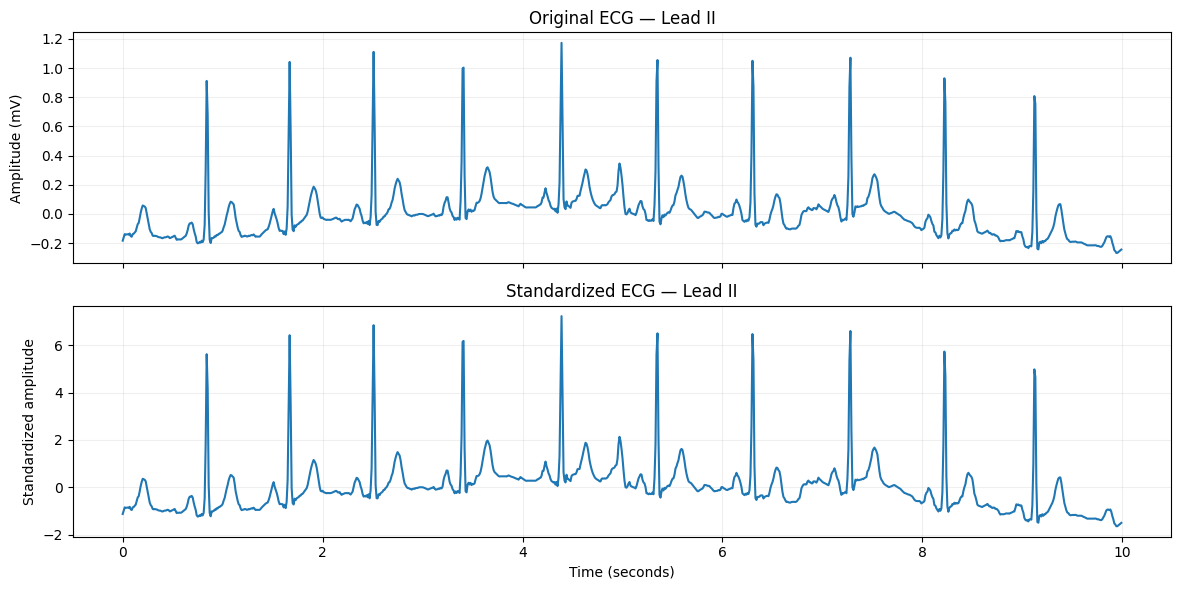

In [17]:
lead_index = 1
time = np.arange(1000) / 100

fig, axes = plt.subplots(
    2, 1,
    figsize=(12, 6),
    sharex=True
)

axes[0].plot(
    time,
    X_train_pilot[0, :, lead_index]
)

axes[0].set_title("Original ECG — Lead II")
axes[0].set_ylabel("Amplitude (mV)")

axes[1].plot(
    time,
    X_train_scaled[0, :, lead_index]
)

axes[1].set_title("Standardized ECG — Lead II")
axes[1].set_ylabel("Standardized amplitude")
axes[1].set_xlabel("Time (seconds)")

for ax in axes:
    ax.grid(alpha=0.2)

plt.tight_layout()

plt.savefig(
    RESULTS / "raw_vs_normalized_ecg.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

**Phase 16: Pipeline Integrity Tests**

Automated assertions verify the essential data pipeline invariants before model development.

These include patient-level and record-level separation, valid binary targets, consistent ECG dimensions, correct tensor layouts, and alignment between datasets and their corresponding samples.

Passing these checks provides evidence of basic pipeline correctness, but does not replace comprehensive testing of preprocessing decisions, dataset completeness, or downstream model evaluation.

In [18]:
assert verify_disjoint_splits(splits)

assert set(y_train_pilot.tolist()) == {0, 1}
assert set(y_val_pilot.tolist()) == {0, 1}

assert len(set(train_ids) & set(val_ids)) == 0

assert X_train_pilot.shape[1:] == (1000, 12)
assert X_val_pilot.shape[1:] == (1000, 12)

assert X_train_tensor.shape[1:] == (12, 1000)
assert X_val_tensor.shape[1:] == (12, 1000)

assert len(train_dataset) == len(pilot_train)
assert len(val_dataset) == len(pilot_val)

print("PASS: Patient-level split integrity.")
print("PASS: Record-level split integrity.")
print("PASS: Binary target validation.")
print("PASS: ECG dimensions.")
print("PASS: PyTorch tensor dimensions.")
print("PASS: DataLoader consistency.")

PASS: Patient-level split integrity.
PASS: Record-level split integrity.
PASS: Binary target validation.
PASS: ECG dimensions.
PASS: PyTorch tensor dimensions.
PASS: DataLoader consistency.


Phase 17: Pilot Pipeline Report Export

In [19]:
pipeline_report = {
    "project": "PTB-XL ECG Classification",
    "dataset_version": "1.0.3",
    "sampling_frequency_hz": 100,
    "signal_shape": [1000, 12],
    "training_records": len(train_df),
    "validation_records": len(val_df),
    "test_records": len(test_df),
    "pilot_training_records": len(pilot_train),
    "pilot_validation_records": len(pilot_val),
    "pilot_train_shape": list(X_train_pilot.shape),
    "pilot_val_shape": list(X_val_pilot.shape),
    "normalization": "channel-wise z-score",
    "normalization_fit": "pilot training only",
    "random_seed": SEED,
    "patient_leakage_detected": False,
    "status": "pilot pipeline validated"
}

with open(
    RESULTS / "pilot_pipeline_report.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(pipeline_report, f, indent=4)

qc_train.to_csv(
    RESULTS / "pilot_train_quality.csv",
    index=False
)

qc_val.to_csv(
    RESULTS / "pilot_val_quality.csv",
    index=False
)

print("Pilot pipeline report saved.")

Pilot pipeline report saved.
